# HFR manual fit
Simulate HFR for a chosen test, compare against experiment, and inspect the membrane λ profile at the final time-step of each current-density point.\
**Workflow:** edit the *Parameters* cell -> run all -> read the plots.

In [1]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve()
while not (PROJECT_ROOT / 'setup.py').exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError('Cannot find project root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from solve_dae.integrate import solve_dae

ROOT = Path("../..").resolve()
sys.path.insert(0, str(ROOT / "scripts" / "Experimental"))

from simulate_HFR import build_cell, build_atol, soc_cutoff_event  # noqa: E402
from rfbmodel1D.parameters.params import membraneparams, cellparams  # noqa: E402
from rfbmodel1D.cells.cell import Cell  # noqa: E402

## -- Parameters -- 

In [2]:
# -- test selection ------------------------------------------------------------
TEST_NO = 25     # integer 1-29

# -- sorption / desorption kinetics --------------------------------------------
k_vw_sorp   = 1.91e-5  # vapour-water sorption rate   [m/s]
S_desorp    = 3.18 # vapour-water desorption rate [m/s]
k_lw_sorp   = 1.04e-4  # liquid-water sorption rate   [m/s]
k_ca_lw     = 7.37e-5 # liquid-water sorption at cathode side [m/s]
R_EXTRA     = 0.0792 /1e4  # extra resistance (e.g. contact resistance) [Ω·m²] (0.1 Ω·cm² converted to Ω·m²)

# -- solver settings -----------------------------------------------------------
TF     = 1800    # simulation duration per point [s]
RTOL   = 1e-5    # relative tolerance for time integration
STRIDE_charg = 1 # use every Nth current-density point (1 = all)
STRIDE_disch = 1 # use every Nth point for discharge (to speed up discharge simulation, which is slower due to more points and lower currents)

In [3]:
# -- apply kinetics to membrane params ----------------------------------------
membraneparams.k_sorp_vw   = k_vw_sorp
membraneparams.k_desorp_vw = S_desorp * k_vw_sorp
membraneparams.k_sorp_lw   = k_lw_sorp
membraneparams.k_desorp_lw = S_desorp * k_lw_sorp
membraneparams.k_ca_lw     = k_ca_lw
membraneparams.sf_D        = 0.5
cellparams.vanadium_uptake = False

# -- load experimental data ----------------------------------------------------
csv  = ROOT / "data" / "experimental" / "HFR.csv"
data = pd.read_csv(csv)
data = data[data["test_no"] == TEST_NO]

soc = data["SOC"].iloc[0]
T   = data["T(°C)"].iloc[0]        # °C
Q_v = data["Q_v (ml/min)"].iloc[0] # ml/min

j_charge    = data[data["mode"] == "charge"]["j_appl (A/m2)"].values[::STRIDE_charg]
j_discharge = data[data["mode"] == "discharge"]["j_appl (A/m2)"].values[::STRIDE_disch]
HFR_exp     = np.concatenate([
    data[data["mode"] == "charge"]["value (ohm cm2)"].values[::STRIDE_charg],
    data[data["mode"] == "discharge"]["value (ohm cm2)"].values[::STRIDE_disch],
])
print(f"Test {TEST_NO}: SOC={soc}, T={T}°C, Q_v={Q_v} ml/min, R_extra={R_EXTRA*1e4:.3f} Ω·cm²")
print(f"Charge points: {len(j_charge)}   Discharge points: {len(j_discharge)}")

Test 25: SOC=0.9, T=32°C, Q_v=45 ml/min, R_extra=0.079 Ω·cm²
Charge points: 12   Discharge points: 14


## Run simulations

In [4]:
def run_sim(j_appl: float):
    """Run one DAE solve.  Returns (HFR [Ohm.cm2], lambda_profile [Nm], x_mem [Nm])."""
    cell, y0, yp0 = build_cell(soc, j_appl, T, Q_v)
    atol = build_atol(cell)
    t0   = time.time()
    jac_sparsity = cell.compute_jac_sparsity(y0, yp0)
    sol  = solve_dae(
        cell.dae_residual_full_cell,
        (0.0, TF), y0, yp0,
        method="BDF", atol=atol, rtol=RTOL,
        events=soc_cutoff_event, jac_sparsity=jac_sparsity
    )
    elapsed = time.time() - t0

    # -- lambda profile at final timestep ------------------------------------
    state       = cell.split_state(sol.y[:, -1])
    lam_profile = state["membrane"][:, 0]           # shape (Nm,)
    x_mem       = cell.mesh.membrane_mesh.x_grid    # normalised 0->1

    # -- sync internal state to final solution point -------------------------
    cell.dae_residual_full_cell(sol.t[-1], sol.y[:, -1], sol.yp[:, -1])

    # -- HFR -----------------------------------------------------------------
    kappa_io_ca = cell.cathode.kappa_io
    sigma_ca    = np.ones_like(kappa_io_ca) * cell.cathode.eff_conductivity
    dx_ca       = cell.mesh.cathode_mesh.dx * cell.cathode.thickness
    R_cathode   = sum(dx_ca / (sigma_ca + kappa_io_ca))

    kappa_io_m  = cell.membrane.kappa_io
    dx_m        = cell.mesh.membrane_mesh.dx * cell.membrane.thickness
    R_membrane  = sum(dx_m / kappa_io_m)

    R_ACL  = cell.anode.thickness  / cell.anode.eff_conductivity
    R_AGDL = cell.agdl.thickness   / cell.agdl.eff_conductivity
    R_BP   = cell.thickness_BP / cell.sigma_BP
    R_CC   = cell.thickness_CC / cell.sigma_CC
    HFR    = (R_cathode + R_membrane + R_ACL + R_AGDL + R_BP + R_CC + R_EXTRA) * 1e4

    print(f"  j={j_appl:+8.0f} A/m2  HFR={HFR:.4f} Ohm.cm2  ({elapsed:.1f}s)")
    return HFR, lam_profile, x_mem


HFR_sim    = []
lam_charge = []
lam_disc   = []
x_mem_ref  = None   # will be set on first solve (same grid for all)

print("=== Charge ===")
for i in range(len(j_charge)):
    j = j_charge[i]     
    hfr, lam, x_mem = run_sim(float(j))
    HFR_sim.append(hfr);  lam_charge.append(lam);  x_mem_ref = x_mem

print("=== Discharge ===")
for i in range(len(j_discharge)):
    j = j_discharge[i]
    hfr, lam, x_mem = run_sim(-float(j))
    HFR_sim.append(hfr);  lam_disc.append(lam)

mse = float(np.mean((np.array(HFR_sim) - HFR_exp) ** 2))
print(f"MSE = {mse:.6f} (Ohm.cm2)^2")

=== Charge ===
  j=     +24 A/m2  HFR=0.5248 Ohm.cm2  (4.4s)
  j=     +95 A/m2  HFR=0.5228 Ohm.cm2  (3.8s)
  j=    +202 A/m2  HFR=0.5200 Ohm.cm2  (5.1s)
  j=    +310 A/m2  HFR=0.5173 Ohm.cm2  (4.4s)
  j=    +440 A/m2  HFR=0.5082 Ohm.cm2  (11.1s)
  j=    +613 A/m2  HFR=0.5088 Ohm.cm2  (14.3s)
  j=    +810 A/m2  HFR=0.5109 Ohm.cm2  (13.2s)
  j=   +1012 A/m2  HFR=0.5165 Ohm.cm2  (12.7s)
  j=   +1244 A/m2  HFR=0.5210 Ohm.cm2  (16.0s)
  j=   +1500 A/m2  HFR=0.5261 Ohm.cm2  (16.6s)
  j=   +1744 A/m2  HFR=0.5313 Ohm.cm2  (20.6s)
  j=   +1994 A/m2  HFR=0.5370 Ohm.cm2  (24.1s)
=== Discharge ===
  j=    -107 A/m2  HFR=0.5290 Ohm.cm2  (3.9s)
  j=    -256 A/m2  HFR=0.5344 Ohm.cm2  (3.8s)
  j=    -506 A/m2  HFR=0.5452 Ohm.cm2  (4.3s)
  j=    -756 A/m2  HFR=0.5580 Ohm.cm2  (3.9s)
  j=   -1006 A/m2  HFR=0.5732 Ohm.cm2  (3.8s)
  j=   -1274 A/m2  HFR=0.5925 Ohm.cm2  (3.6s)
  j=   -1530 A/m2  HFR=0.6143 Ohm.cm2  (3.5s)
  j=   -1780 A/m2  HFR=0.6395 Ohm.cm2  (3.6s)
  j=   -2030 A/m2  HFR=0.6696 Ohm.cm2  

## Results

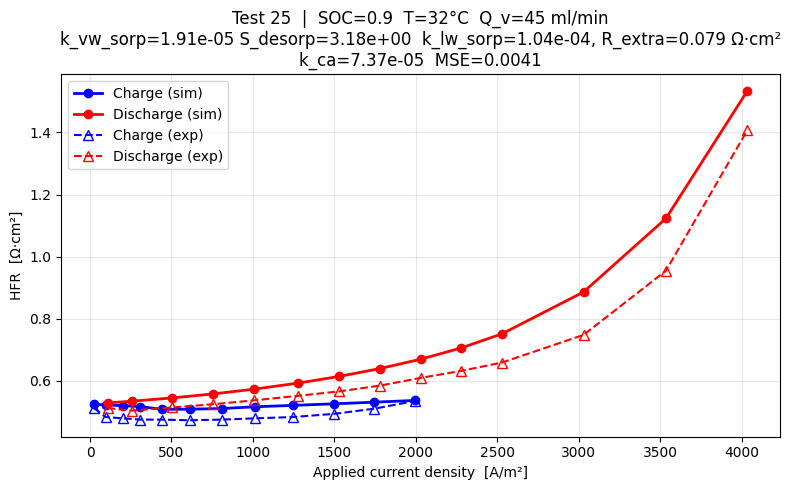

In [5]:
# -- HFR: simulated vs experimental -------------------------------------------
nc, nd = len(j_charge), len(j_discharge)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(j_charge,    HFR_sim[:nc],  'b-o',  lw=2, ms=6, label='Charge (sim)')
ax.plot(j_discharge, HFR_sim[nc:],  'r-o',  lw=2, ms=6, label='Discharge (sim)')
ax.plot(j_charge,    HFR_exp[:nc],  'b^--', lw=1.5, ms=7, mfc='none', label='Charge (exp)')
ax.plot(j_discharge, HFR_exp[nc:],  'r^--', lw=1.5, ms=7, mfc='none', label='Discharge (exp)')
ax.set_xlabel('Applied current density  [A/m²]')
ax.set_ylabel('HFR  [Ω·cm²]')
ax.set_title(
    f'Test {TEST_NO}  |  SOC={soc}  T={T}°C  Q_v={Q_v} ml/min\n'
    f'k_vw_sorp={k_vw_sorp:.2e} S_desorp={S_desorp:.2e}  k_lw_sorp={k_lw_sorp:.2e}, R_extra={R_EXTRA*1e4:.3f} Ω·cm²\n'
    f'k_ca={k_ca_lw:.2e}  MSE={mse:.4f}'
)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

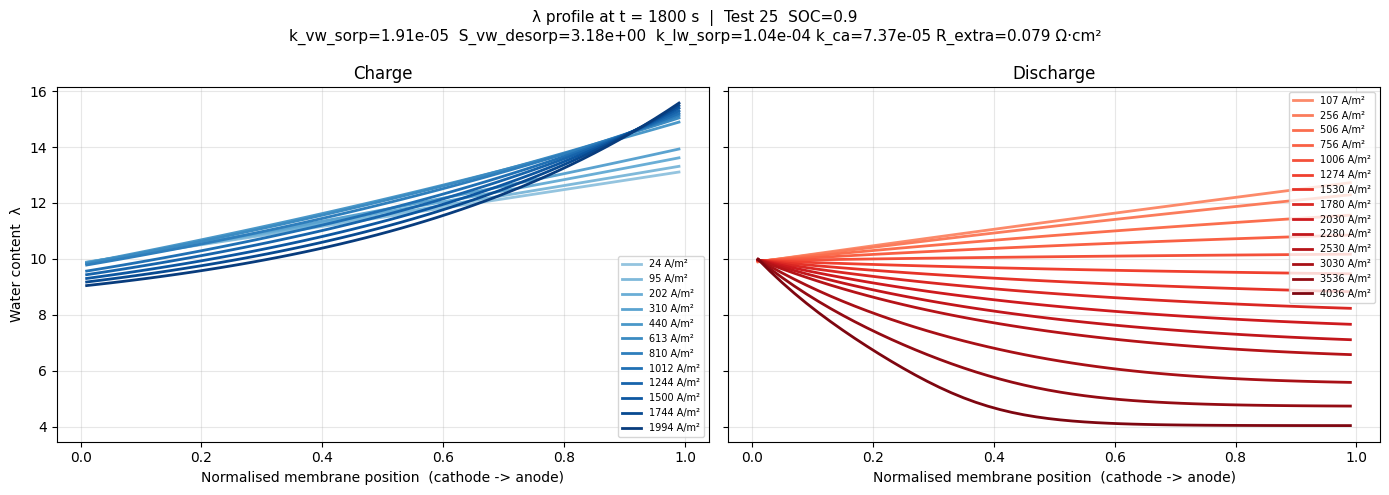

In [6]:
# -- Membrane λ profiles at final time ----------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

colors_c = plt.cm.Blues(np.linspace(0.4, 0.95, max(nc, 1)))
for lam, j, c in zip(lam_charge, j_charge, colors_c):
    axes[0].plot(x_mem_ref, lam, color=c, lw=2, label=f'{j:.0f} A/m²')
axes[0].set_xlabel('Normalised membrane position  (cathode -> anode)')
axes[0].set_ylabel('Water content  λ')
axes[0].set_title('Charge')
axes[0].legend(fontsize=7, loc='best')
axes[0].grid(True, alpha=0.3)

colors_d = plt.cm.Reds(np.linspace(0.4, 0.95, max(nd, 1)))
for lam, j, c in zip(lam_disc, j_discharge, colors_d):
    axes[1].plot(x_mem_ref, lam, color=c, lw=2, label=f'{j:.0f} A/m²')
axes[1].set_xlabel('Normalised membrane position  (cathode -> anode)')
axes[1].set_title('Discharge')
axes[1].legend(fontsize=7, loc='best')
axes[1].grid(True, alpha=0.3)

fig.suptitle(
    f'λ profile at t = {TF} s  |  Test {TEST_NO}  SOC={soc}\n'
    f'k_vw_sorp={k_vw_sorp:.2e}  S_vw_desorp={S_desorp:.2e}  k_lw_sorp={k_lw_sorp:.2e} k_ca={k_ca_lw:.2e} R_extra={R_EXTRA*1e4:.3f} Ω·cm²',
    fontsize=11
)
plt.tight_layout()
plt.show()